# Overnight jumps that read the end of the session

In `basic_jump_equation.ipynb` the data are a plain geometric Brownian motion (GBM). There every
overnight jump is independent of everything before it, so the null model is true by
construction. This notebook changes the data-generating process so that **the jump depends on
how the previous session ended**: on the least-squares slope $\hat d_{t-1}$ of the last 20% of
yesterday's curve. The intraday curves stay exactly the GBM's. Only the nights are replaced.

With $P = 100\log S$, the curves $X_t(s) = P_t(s) - P_t(0)$ and the night length $T$:

$$
\begin{aligned}
X_t(s) &= 100\,m\,s + 100\,\sigma\,W_t(s) && \text{the GBM's sessions, unchanged} \\
\hat d_{t-1} &= \text{least-squares slope of } X_{t-1}(s) \text{ on } s \text{ over } s \in [0.8, 1] && \text{a statistic of yesterday's curve, \% per session} \\
J_t &= 100\,m\,T + \kappa\,T\,(\hat d_{t-1} - 100\,m) + 100\,\sigma\sqrt{T}\,Z_t, \quad Z_t \overset{\text{iid}}{\sim} N(0,1) && \text{the new overnight jump} \\
P_t(s) &= P_{t-1}(1) + J_t + X_t(s) && \text{the prices, restitched}
\end{aligned}
$$

Everything in this DGP rests on $\hat d$, so section 2 is about nothing else: what it is, how it
is computed, its exact distribution, and how to make valid inference with it. The short version
is that $\hat d$ is *not* the drift. It is almost entirely the direction the price happened to
move in over the last 78 minutes, and that is what the jump responds to.

| choice | setting | why |
|---|---|---|
| window | the last 20% of the session, $s \in [0.8, 1]$ (78 one-minute bars) | the part of the day that is meant to inform the night |
| statistic of the window | its least-squares slope $\hat d$ | a linear functional of the curve with an ordinary coefficient function, so the jump equation is exactly the notes' basic model with a known $\beta(u)$ (section 5) |
| night's variance | the GBM's, $(100\sigma)^2 T$ | the window's realised variance is available as a switch (section 6), but under a constant $\sigma$ it carries almost no information |
| $\kappa$ | 0, 0.25, 0.5 and 1 | how much of the window's slope the night carries on (section 3) |

Everything else (63 days, one-minute bars, $S_0 = 100$, $\sigma = 0.01$, $T = 0.25$,
$\nu = 2.5\times10^{-4}$, seed 0) is as in the null notebook. The code is `jump.window_dgp`, and
`tests/test_window_jump.py` checks it. **Nothing is fitted here.** This notebook only builds the
data and checks that they are what they claim to be; fitting $\beta(u)$ is the next step.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from fts_research.core import style
from fts_research.jump import basic_dgp as bd
from fts_research.jump import basic_est as be
from fts_research.jump import window_dgp as wd

style.use(plt)
pd.set_option("display.width", 120)
BLUE, ORANGE, _ = style.CATEGORICAL

## 1. The GBM sessions

The GBM is simulated exactly as in the null notebook, with the same seed, so the 63 curves are
the same 63 curves. Its overnight increments are then thrown away. Two things are worth saying
about what replaces them.

**No overnight path is simulated.** The original idea was to run a new GBM over the night, with
parameters taken from the window. But a GBM run for a time $T$ with log drift $d$ and variance
rate $v$ ends at a log price that is exactly $N(dT,\, vT)$ from where it started, and the jump is
that end point and nothing else. One normal draw per night is therefore the same thing as
simulating the night's path and keeping its end. Writing the rule for the log price directly
also keeps the Itô term $\sigma^2/2$ out of it.

**A burn-in curve makes the first jump.** $J_1$ is the night before session 1, so it needs a
session 0 to read. One extra curve $X_0$ is drawn from the same GBM and used only for that, so
all 63 jumps follow the same law. $X_0$ is not part of the sample. It is drawn *after* the 63
sessions, which is what keeps those sessions identical to the null notebook's.

In [2]:
n_days, n_bars = 63, 390          # three months of one-minute sessions, as in the null notebook
S0, sigma, T, nu = 100.0, 0.01, 0.25, 2.5e-4
start = 0.8                         # the window: the last 20% of the session
KAPPAS = (0.0, 0.25, 0.5, 1.0)
gbm = dict(n_days=n_days, n_bars=n_bars, S0=S0, sigma=sigma, T=T, nu=nu)

# One seed for every kappa: the curves, the burn-in curve and the noise Z are the same draws in
# each run, so the jumps differ only by the signal.
sims = {k: wd.window_jump_sessions(**gbm, start=start, kappa=k, rng=np.random.default_rng(0))
        for k in KAPPAS}
sim = sims[1.0]
s, X, X0 = sim["s"], sim["X"], sim["X0"]

null_X = bd.split_sessions(bd.gbm_sessions(**gbm, rng=np.random.default_rng(0))["S"], S0)[1]
print(f"curves: {X.shape[0]} sessions x {X.shape[1]} grid points, plus one burn-in curve")
print(f"identical to the null notebook's curves: {np.array_equal(X, null_X)}")
print(f"the same curves at every kappa: "
      f"{all(np.array_equal(sims[k]['X'], X) for k in KAPPAS)}")
print(f"window [{start}, 1]: {int((s >= start - 1e-12).sum())} grid points, "
      f"{int((s >= start - 1e-12).sum()) - 1} one-minute bars")

curves: 63 sessions x 391 grid points, plus one burn-in curve
identical to the null notebook's curves: True
the same curves at every kappa: True
window [0.8, 1]: 79 grid points, 78 one-minute bars


## 2. What $\hat d$ is

Write the window as $[a, 1]$, with $a = 0.8$, width $w = 1 - a = 0.2$ and midpoint
$\bar u = (1 + a)/2 = 0.9$. This section works through $\hat d$ in four steps:

1. its definition, and how it is computed from a curve;
2. an equivalent form, as a weighted average of the window's returns;
3. its exact distribution under the model;
4. confidence intervals: the correct one, and why the textbook regression one is badly wrong.

It ends with what all this means for the DGP and for inference on it.

### 2.1 Definition

$\hat d_{t-1}$ is the slope of the straight line fitted by least squares to yesterday's curve
over the window:

$$
(\hat c, \hat d_{t-1}) = \arg\min_{c,\,b} \int_a^1 \big(X_{t-1}(u) - c - b\,u\big)^2\,\mathrm{d}u
\quad\Longrightarrow\quad
\hat d_{t-1} = \frac{\int_a^1 (u - \bar u)\,X_{t-1}(u)\,\mathrm{d}u}{\int_a^1 (u - \bar u)^2\,\mathrm{d}u}
= \frac{12}{w^3}\int_a^1 (u - \bar u)\,X_{t-1}(u)\,\mathrm{d}u .
$$

On the grid it is the ordinary least-squares slope through the window's 79 points,

$$
\hat d_{t-1} = \sum_k c_k\,X_{t-1}(s_k), \qquad c_k = \frac{s_k - \bar s}{\sum_j (s_j - \bar s)^2}\ \text{ for } s_k \ge a,\quad c_k = 0 \text{ otherwise},
$$

which is `wd.window_slope_weights`. It is a **statistic**: a fixed weighted sum of numbers we
observe, with no parameter in it. Because $\sum_k c_k = 0$, adding a constant to the curve does
not change it. So the return made before 0.8 has no effect, and only the shape of the curve
inside the window counts.

The figure shows it on the two sessions with the steepest late rise and the steepest late fall.
The grey line is the whole session and the shaded band is the window. The blue line is the
least-squares line fitted inside the window, and $\hat d$ is its slope, in percent per session.

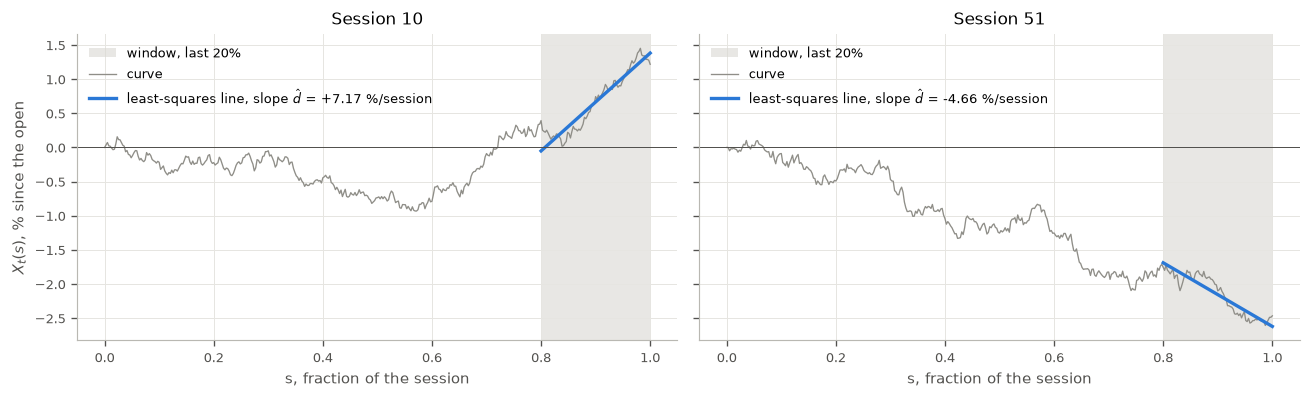

weights c_k: 79 non-zero (the window's points), sum c = 2.6e-14, sum c s = 1.000000
c @ X agrees with np.polyfit on every curve: True


In [3]:
on = s >= start - 1e-12
before = np.vstack([X0, X[:-1]])               # the curve before each jump
d = wd.window_slope(before, s, start)          # dhat_{t-1}, one per jump
days = [int(np.argmax(d[1:])) + 1, int(np.argmin(d[1:])) + 1]   # steepest up and down

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, t in zip(axes, days):
    x = before[t]
    intercept = x[on].mean() - d[t] * s[on].mean()
    ax.axvspan(start, 1, color=style.BAND, alpha=0.6, lw=0, label="window, last 20%")
    ax.plot(s, x, color=style.CONTROL, lw=0.8, label="curve")
    ax.plot(s[on], intercept + d[t] * s[on], color=BLUE, lw=2,
            label=fr"least-squares line, slope $\hat d$ = {d[t]:+.2f} %/session")
    ax.axhline(0, color=style.MUTED, lw=0.6)
    ax.set_title(f"Session {t}")
    ax.set_xlabel("s, fraction of the session")
    ax.legend(loc="upper left")
axes[0].set_ylabel(r"$X_t(s)$, % since the open")
fig.tight_layout()
style.save_figure(fig, "window_jump_slope")
plt.show()

c = wd.window_slope_weights(s, start)
print(f"weights c_k: {np.count_nonzero(c)} non-zero (the window's points), "
      f"sum c = {c.sum():.1e}, sum c s = {c @ s:.6f}")
print(f"c @ X agrees with np.polyfit on every curve: "
      f"{np.allclose(d, [np.polyfit(s[on], x[on], 1)[0] for x in before])}")

The weights do what the formula says: 79 of them are non-zero, they sum to zero, and they
return exactly 1 for the line $s$ itself. The weighted sum agrees with `np.polyfit` on every
curve.

### 2.2 The same number, as a weighted average of returns

A curve is the running sum of its one-minute returns, $X(s_j) = \sum_{k \le j} \Delta X_k$.
Substituting that into the weighted sum and swapping the order of summation gives

$$
\hat d = \sum_k g_k\,\Delta X_k, \qquad g_k = \sum_{j \ge k} c_j, \qquad \sum_k g_k\,\Delta s_k = 1 .
$$

So $\hat d$ is a weighted average of the returns per unit time, $\Delta X_k / \Delta s_k$, with
weights $g_k\,\Delta s_k$ that sum to one (`wd.window_return_weights`). Every return before the
window gets weight zero, up to rounding. On a fine grid $g$ is the parabola
$g(v) = \tfrac{6}{w^3}\big[(w/2)^2 - (v - \bar u)^2\big]$.

The figure plots $g$ for each one-minute return, next to the flat weight $1/w$ of the endpoint
return $(X(1) - X(0.8))/w$, the other natural measure of the window's trend.

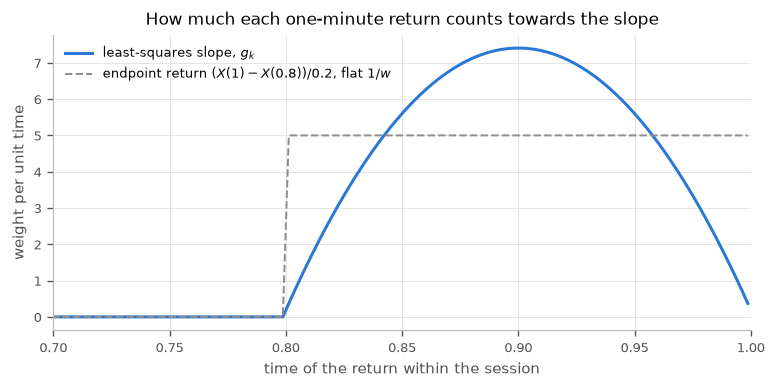

slope from the returns, sum g_k dX_k, equals c @ X: True
the weights g_k ds_k sum to 1.000000; returns before 0.8 get weight 2.6e-14


In [4]:
g = wd.window_return_weights(s, start)        # one weight per one-minute return
mid = 0.5 * (s[1:] + s[:-1])
w = 1 - start
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(mid, g, color=BLUE, lw=1.8, label=r"least-squares slope, $g_k$")
ax.plot(mid, np.where(mid > start, 1 / w, 0.0), color=style.CONTROL, lw=1.2, ls="--",
        label=r"endpoint return $(X(1) - X(0.8))/0.2$, flat $1/w$")
ax.set_xlim(0.7, 1.0)
ax.set_title("How much each one-minute return counts towards the slope")
ax.set_xlabel("time of the return within the session")
ax.set_ylabel("weight per unit time")
ax.legend(loc="upper left")
style.save_figure(fig, "window_jump_weights")
plt.show()

print(f"slope from the returns, sum g_k dX_k, equals c @ X: "
      f"{np.allclose(np.diff(before, axis=1) @ g, d)}")
print(f"the weights g_k ds_k sum to {g @ np.diff(s):.6f}; returns before 0.8 get weight "
      f"{np.abs(g[mid < start]).max():.1e}")

The least-squares slope counts the returns in the middle of the window most, peaking at
$1.5/w = 7.5$ at 0.9, and those at its two ends hardly at all. The endpoint return counts them
all equally. Both are averages of the same 78 returns, and the choice between them is a choice
of model, not of estimator: it says *which* of yesterday's returns tonight's jump responds to.

The endpoint return is the GBM's maximum-likelihood drift estimate from the window, and its
variance is 20% smaller ($\sigma^2/w$ against $1.2\sigma^2/w$). We use the least-squares slope
anyway because its coefficient function $\beta(u)$ is an ordinary function (section 5). The
endpoint return's $\beta$ is two spikes, one at 0.8 and one at 1, which a functional
regression cannot represent.

### 2.3 Its distribution

Under the model each return in the window is the drift's share plus Brownian noise,
$\Delta X_k = 100m\,\Delta s_k + \sigma_\varepsilon\,\Delta W_k$, with $\sigma_\varepsilon = 100\sigma$.
Substituting into the weighted average,

$$
\hat d_{t-1} = \underbrace{100\,m}_{d_\mu,\ \text{the drift}} + \sigma_\varepsilon\,\xi_{t-1},
\qquad \xi_{t-1} = \sum_k g_k\,\Delta W_{t-1,k} .
$$

The first term uses $\sum_k g_k \Delta s_k = 1$. The Brownian increments are independent
$N(0, \Delta s_k)$, so $\xi$ is Gaussian with variance $\sum_k g_k^2\,\Delta s_k$. Hence,
exactly,

$$
\hat d_{t-1} \sim N\Big(d_\mu,\ \sigma_\varepsilon^2 \sum_k g_k^2\,\Delta s_k\Big),
\qquad \sum_k g_k^2\,\Delta s_k \approx \int_a^1 g(v)^2\,\mathrm{d}v = \frac{1.2}{w},
$$

and $\hat d_{t-1}$ is i.i.d. over days, because the sessions are. `wd.window_slope_sd` computes
the standard deviation on the grid. The cell prints it and checks the whole statement on
20,000 fresh sessions.

In [5]:
truth0 = wd.window_jump_truth(s, sigma, T, nu, start, kappa=0.0)
sd_d = truth0["sd_slope"]
print(f"true drift d_mu = 100 m = {truth0['d_mu']:.4f} %/session")
print(f"sd(dhat) = sigma_eps sqrt(sum g^2 ds) = {sd_d:.4f} on this grid "
      f"(continuum sqrt(1.2 / w) = {np.sqrt(1.2 / w):.4f}): {sd_d / truth0['d_mu']:.0f} times the drift")

# Check the distribution on 20,000 fresh sessions.
many = bd.split_sessions(bd.gbm_sessions(n_days=20_000, n_bars=n_bars, S0=S0, sigma=sigma, T=T,
                                         nu=nu, rng=np.random.default_rng(7))["S"], S0)[1]
d_many = wd.window_slope(many, s, start)
print(f"20,000 sessions: mean {d_many.mean():+.4f} (se {sd_d / np.sqrt(d_many.size):.4f}), "
      f"sd {d_many.std(ddof=1):.4f}, Jarque-Bera p = {stats.jarque_bera(d_many).pvalue:.2f}")
print(f"lag-1 correlation of dhat across days: {np.corrcoef(d_many[:-1], d_many[1:])[0, 1]:+.4f}")

true drift d_mu = 100 m = 0.0200 %/session
sd(dhat) = sigma_eps sqrt(sum g^2 ds) = 2.4343 on this grid (continuum sqrt(1.2 / w) = 2.4495): 122 times the drift


20,000 sessions: mean +0.0522 (se 0.0172), sd 2.4508, Jarque-Bera p = 0.56
lag-1 correlation of dhat across days: -0.0090


$\hat d$ is centred on the drift, $d_\mu = 0.02\%$ per session, but its standard deviation is
2.43%, **122 times the drift**. The 20,000 sessions agree with every part of the claim:

- the mean, +0.052, is within two standard errors (0.017) of the drift;
- the standard deviation, 2.451, is within 1.4 standard errors of 2.434;
- Jarque-Bera finds no departure from normality (p = 0.56);
- successive days are uncorrelated (−0.009, against a standard error of 0.007).

So one session's $\hat d$ is almost entirely $\sigma_\varepsilon\xi$, the random wander of the
window, and almost none of it is the drift.

### 2.4 Confidence intervals: the right one and the textbook one

Suppose we did want to read $\hat d$ as an estimate of the drift $d_\mu$. Three 95% intervals
from a single session:

- **Textbook OLS.** Treat the 79 points as a regression, $X(s_k) = c + b\,s_k + e_k$ with
  independent errors, and use the usual standard error of a slope,
  $\sqrt{\hat\sigma_e^2/\sum_k (s_k - \bar s)^2}$, with a $t_{77}$ quantile. **This is wrong
  here.** A Brownian path's deviations from a line are not independent: neighbouring points
  share almost all of their history. The formula treats 79 heavily overlapping points as 79
  separate pieces of information.
- **Brownian, $\sigma_\varepsilon$ known.** $\hat d \pm 1.96\,\sigma_\varepsilon\sqrt{\sum_k g_k^2\,\Delta s_k}$,
  from 2.3. It is exact.
- **Brownian, $\sigma_\varepsilon$ estimated from the window.** The same, with $\sigma_\varepsilon$
  taken from the window's own realised variance and a $t_{77}$ quantile, which is what can be
  computed from one session alone. $\hat d$ and that realised variance come from the same
  returns, so they are not exactly independent, but the effect is too small to measure: this
  interval covered 95.03% of 500,000 simulated sessions.

`wd.window_slope_ci` gives the last two. The table scores all three on the 20,000 sessions
of 2.3.

In [6]:
# Three 95% intervals for d_mu from one session's dhat, on the 20,000 sessions above.
on_s, X_on = s[on], many[:, on]
resid = X_on - X_on.mean(axis=1, keepdims=True) - np.outer(d_many, on_s - on_s.mean())
se_ols = np.sqrt((resid**2).sum(axis=1) / (on_s.size - 2) / ((on_s - on_s.mean()) ** 2).sum())
ols = d_many[:, None] + np.outer(stats.t.ppf(0.975, on_s.size - 2) * se_ols, [-1, 1])
known = wd.window_slope_ci(many, s, start, sigma_eps=100 * sigma)
plug_in = wd.window_slope_ci(many, s, start)

def summary(ci):
    covered = (ci[:, 0] <= truth0["d_mu"]) & (truth0["d_mu"] <= ci[:, 1])
    return {"coverage": covered.mean(), "mean half-width": 0.5 * (ci[:, 1] - ci[:, 0]).mean()}

ci_table = pd.DataFrame({
    "textbook OLS (t, 77 df)": summary(ols),
    "Brownian, sigma_eps known": summary(known),
    "Brownian, sigma_eps from the window (t, 77 df)": summary(plug_in)}).T
print(f"textbook OLS standard error is {sd_d / se_ols.mean():.1f} times too small on average")
fit = be.fit_null(sims[0.0]["J"], X, s)
print(f"sigma_eps from fit_null on the 63 sample days: {fit['sigma_eps']:.4f}, "
      f"95% interval {fit['sigma_eps_ci'].round(4)}")
ci_table.round(4)

textbook OLS standard error is 11.2 times too small on average
sigma_eps from fit_null on the 63 sample days: 0.9958, 95% interval [0.987  1.0047]


,coverage,mean half-width
"textbook OLS (t, 77 df)",0.1362,0.4325
"Brownian, sigma_eps known",0.9495,4.7712
"Brownian, sigma_eps from the window (t, 77 df)",0.9480,4.8362


The textbook interval is **11.2 times too narrow** and covers the true drift only 13.6% of the
time. Both Brownian intervals cover 95% to Monte Carlo error (94.95% and 94.80%, against a
standard error of 0.15%), and both are about $\pm 4.8\%$ per session wide.

In practice $\sigma_\varepsilon$ is effectively known. Pooled over days it is pinned down to
under half a percent: `be.fit_null` on the 63 sample sessions gives 0.9958, with interval
$[0.987, 1.005]$. So the known-$\sigma_\varepsilon$ interval is the one to use.

The figure shows the two intervals on the first 20 sample sessions, with the true drift as the
dashed line.

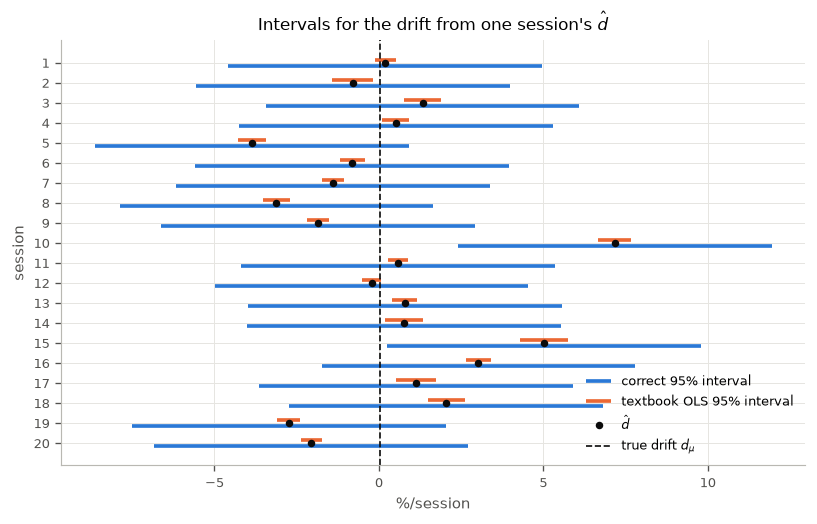

cover the true drift: textbook OLS 2 of 20, correct 18 of 20


In [7]:
# The same intervals on the first 20 sample sessions.
first = before[1:21]
ci_b = wd.window_slope_ci(first, s, start, sigma_eps=100 * sigma)
Xf = first[:, on]
df_ = wd.window_slope(first, s, start)
res_f = Xf - Xf.mean(axis=1, keepdims=True) - np.outer(df_, on_s - on_s.mean())
half_ols = stats.t.ppf(0.975, on_s.size - 2) * np.sqrt(
    (res_f**2).sum(axis=1) / (on_s.size - 2) / ((on_s - on_s.mean()) ** 2).sum())
rows = np.arange(1, 21)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hlines(rows + 0.15, ci_b[:, 0], ci_b[:, 1], color=BLUE, lw=2.2, label="correct 95% interval")
ax.hlines(rows - 0.15, df_ - half_ols, df_ + half_ols, color=ORANGE, lw=2.2,
          label="textbook OLS 95% interval")
ax.plot(df_, rows, "o", color=style.INK, ms=3.5, label=r"$\hat d$")
ax.axvline(truth0["d_mu"], color=style.INK, lw=1, ls="--", label=r"true drift $d_\mu$")
ax.set_yticks(rows)
ax.invert_yaxis()
ax.set_xlabel("%/session")
ax.set_ylabel("session")
ax.set_title(r"Intervals for the drift from one session's $\hat d$")
ax.legend(loc="lower right", fontsize=7.5)
style.save_figure(fig, "window_jump_intervals")
plt.show()
covered_ols = np.abs(df_ - truth0["d_mu"]) <= half_ols
covered_b = (ci_b[:, 0] <= truth0["d_mu"]) & (truth0["d_mu"] <= ci_b[:, 1])
print(f"cover the true drift: textbook OLS {covered_ols.sum()} of 20, correct {covered_b.sum()} of 20")

The textbook intervals (orange) are short and centred on $\hat d$, so they miss the drift
whenever the window happened to trend: they cover it in 2 of 20 sessions. The correct
intervals (blue) are about $\pm 4.8$ wide and cover it in 18 of 20. Even that width says one
session cannot tell the drift's sign. Pooling all 63 sessions would narrow it to about
$\pm 0.6$, still thirty times the drift.

### 2.5 What this means for the DGP, and for inference on it

- **The jump responds to $\hat d$, not to the drift.** The drift $d_\mu$ is the same every day,
  so on its own it could predict nothing. Everything predictable in the jump comes from the
  other term:

  $$
  J_t = \alpha + \kappa\,T\,\sigma_\varepsilon\,\xi_{t-1} + \eta_t, \qquad
  \xi_{t-1} = \sum_k g_k\,\Delta W_{t-1,k} .
  $$

  The hypothesis this DGP builds in is **late-session momentum**: tonight's jump continues the
  direction yesterday's last 78 minutes actually moved in, weighted by the parabola of 2.2.
- **The interval of 2.4 is not the uncertainty that matters for the jump.** It measures how
  badly $\hat d$ estimates the drift. The jump is defined by $\hat d$ itself, which we observe
  without error. So regressing $J_t$ on $\hat d_{t-1}$ is an ordinary regression on an
  exactly measured regressor, with no errors-in-variables problem, and inference on $\kappa T$
  is the usual regression inference. Section 4 checks that over 500 simulated quarters.
- **The textbook OLS formula should never be used for the slope of a Brownian curve.** Wherever
  an uncertainty for $\hat d$ is needed, it comes from the increments, as in 2.3 and 2.4.

## 3. The jumps, at four strengths, and the restitched prices

**$\kappa$ is a dial.** It sets how much of yesterday's window slope the night carries on:

$$
J_t = \underbrace{100\,m\,T}_{\text{GBM mean}} + \kappa\,T\,(\hat d_{t-1} - 100\,m) + \underbrace{100\,\sigma\sqrt{T}\,Z_t}_{\text{GBM noise}}.
$$

- $\kappa = 0$ ignores the window. The jump is then $N(100mT,\ 10^4\sigma^2T)$, the GBM's own
  jump law, so this is the null model.
- $\kappa = 1$ carries the window's slope through the night in full. This is the original
  proposal, the window's slope used directly as the night's GBM drift, and it is strong:
  because the night ($T = 0.25$) is longer than the window ($0.2$), it repeats about 1.25 times
  the late-session move.
- In between, the night carries on a share $\kappa$ of it. A negative $\kappa$ would be a
  reversal.

The noise is kept at the GBM's size, so $\mathrm{Var}(J_t) = \kappa^2T^2\,\mathrm{Var}(\hat d) +
10^4\sigma^2T$ grows with $\kappa$. $R^2$ is the share of that variance which yesterday's curve
predicts. All four runs use the same seed: the curves, the burn-in curve and $Z$ are the same
draws in each, so the jumps differ only by the signal. The "true" columns come from
`wd.window_jump_truth`, exact on the grid. The "sample" columns are these 63 days.

In [8]:
rows = []
for k in KAPPAS:
    tr = wd.window_jump_truth(s, sigma, T, nu, start, kappa=k)
    J = sims[k]["J"]
    rows.append({"kappa": k, "kappa T": tr["kappa_T"], "alpha": tr["alpha"],
                 "sd(J) true": tr["sd_J"], "sd(J) sample": J.std(ddof=1),
                 "R2 true": tr["r2"], "R2 sample": np.corrcoef(J, d)[0, 1] ** 2})
table = pd.DataFrame(rows).set_index("kappa")
table.round(4)

,kappa T,alpha,sd(J) true,sd(J) sample,R2 true,R2 sample
kappa,,,,,,
0.00,0.0000,0.0050,0.5000,0.5393,0.0000,0.0238
0.25,0.0625,0.0038,0.5226,0.5806,0.0847,0.1576
0.50,0.1250,0.0025,0.5853,0.6532,0.2703,0.3345
1.00,0.2500,0.0000,0.7876,0.8578,0.5970,0.6142


The $\kappa = 1$ row is the original proposal: $R^2 = 0.60$, with the jump's standard deviation
rising from 0.50% to 0.79%. At $\kappa = 0.25$ the previous curve predicts 8.5% of the jump.
The sample values run above the truth at every $\kappa$ because the four rows share one draw
of the noise $Z$, and it happens to be a large one that leans the same way as $\hat d$. The
$\kappa = 0$ row is that noise alone: its standard deviation is 0.539 against 0.5, and it
"explains" $R^2 = 0.024$ of itself through $\hat d$ by chance. Section 4's Monte Carlo shows the
sample values are right on average.

The $\kappa = 0$ jumps have the null's law but are not the null notebook's jumps. Those were the
GBM's own night increments, which are discarded here, and $Z$ is a new draw.

**The restitching doesn't matter.** Replacing the jumps moves each session up or down, so that
it opens at yesterday's close plus the new jump. That leaves the sessions themselves untouched.
A GBM's log increments over separate intervals are independent, so the sessions never depended
on the nights between them. They are still i.i.d. Brownian curves, and only the gaps change.
The figure shows both price paths.

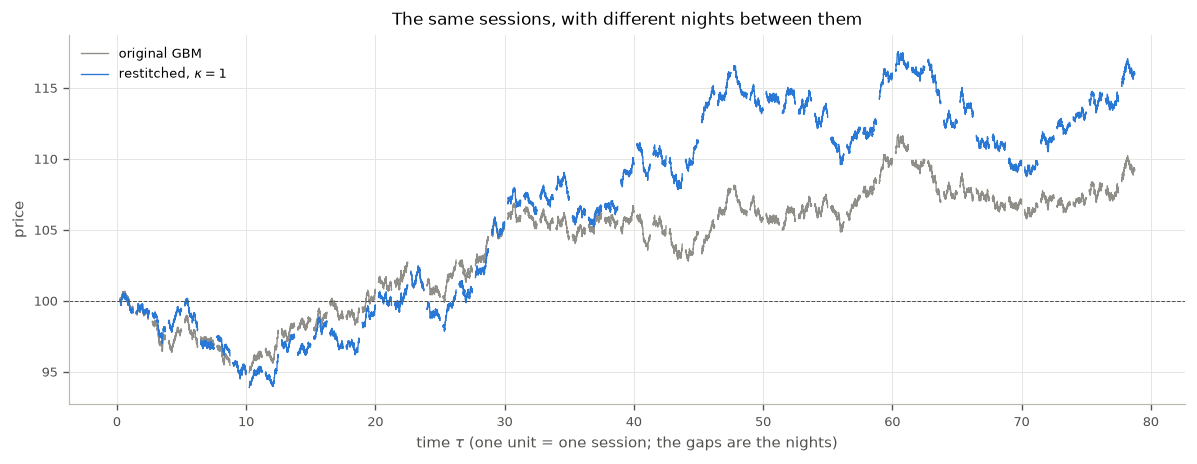

last close: GBM 109.18, restitched 115.95
session shapes unchanged: largest difference in X_t(s) 1.1e-13


In [9]:
a = np.arange(1, n_days + 1) * (1 + T) - 1          # session start times, as in basic_dgp
fig, ax = plt.subplots(figsize=(12, 4))
for t in range(n_days):
    ax.plot(a[t] + s, sim["S_gbm"][t], color=style.CONTROL, lw=0.8,
            label="original GBM" if t == 0 else None)
    ax.plot(a[t] + s, sim["S"][t], color=BLUE, lw=0.8,
            label=r"restitched, $\kappa = 1$" if t == 0 else None)
ax.axhline(S0, color=style.MUTED, lw=0.6, ls="--")
ax.set_title("The same sessions, with different nights between them")
ax.set_xlabel(r"time $\tau$ (one unit = one session; the gaps are the nights)")
ax.set_ylabel("price")
ax.legend(loc="upper left")
style.save_figure(fig, "window_jump_prices")
plt.show()

print(f"last close: GBM {sim['S_gbm'][-1, -1]:.2f}, restitched {sim['S'][-1, -1]:.2f}")
print(f"session shapes unchanged: largest difference in X_t(s) "
      f"{np.abs(bd.split_sessions(sim['S'], S0)[1] - bd.split_sessions(sim['S_gbm'], S0)[1]).max():.1e}")

Grey is the original GBM and blue the same 63 sessions with the $\kappa = 1$ nights between
them. Each blue session has exactly the shape of the grey one above or below it (the largest
difference in any $X_t(s)$ is rounding, $10^{-13}$); it has only been shifted. The shifts
accumulate, so the two paths drift apart, closing the quarter at 109.18 and 115.95. Positive
$\kappa$ is overnight momentum: a session that ended rising tends to open higher.

## 4. Does the end of yesterday's session predict tonight's jump?

Each panel plots the 63 jumps against the window slope of the session before them, one panel
per $\kappa$. The dashed line is the true conditional mean of the jump given that slope,
$\alpha + \kappa T \hat d$, with $\alpha = 100mT(1-\kappa)$.

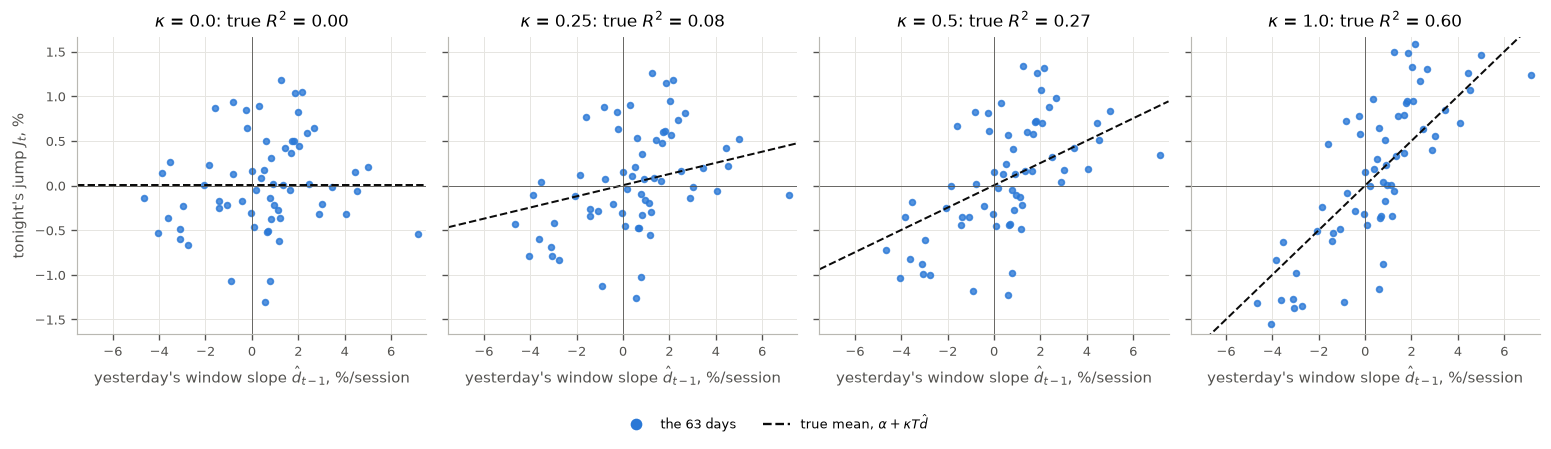

In [10]:
lim_d = 1.05 * np.abs(d).max()
lim_j = 1.05 * max(np.abs(sims[k]["J"]).max() for k in KAPPAS)
xs = np.array([-lim_d, lim_d])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharex=True, sharey=True)
for ax, k in zip(axes, KAPPAS):
    tr = wd.window_jump_truth(s, sigma, T, nu, start, kappa=k)
    ax.plot(d, sims[k]["J"], "o", ms=3.5, color=BLUE, alpha=0.8)
    ax.plot(xs, tr["alpha"] + tr["kappa_T"] * xs, color=style.INK, lw=1.2, ls="--")
    ax.axhline(0, color=style.MUTED, lw=0.5)
    ax.axvline(0, color=style.MUTED, lw=0.5)
    ax.set_xlim(-lim_d, lim_d)
    ax.set_ylim(-lim_j, lim_j)
    ax.set_title(fr"$\kappa$ = {k}: true $R^2$ = {tr['r2']:.2f}")
    ax.set_xlabel(r"yesterday's window slope $\hat d_{t-1}$, %/session")
axes[0].set_ylabel(r"tonight's jump $J_t$, %")
fig.legend(handles=[plt.Line2D([], [], color=BLUE, marker="o", ls="", label="the 63 days"),
                    plt.Line2D([], [], color=style.INK, ls="--",
                               label=r"true mean, $\alpha + \kappa T \hat d$")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
style.save_figure(fig, "window_jump_scatter")
plt.show()

At $\kappa = 0$ the cloud is flat. As $\kappa$ grows it tilts along the true line and its
vertical spread around the line stays the same, because the noise does not change. By
$\kappa = 1$ the end of yesterday's session predicts most of the jump. Since every panel uses
the same $Z$, each point moves straight up or down from one panel to the next.

One sample can mislead, so the next cell checks the DGP over 500 fresh quarters. Each quarter
is regressed on the observed $\hat d_{t-1}$, which (2.5) is an exactly measured regressor, so
the ordinary regression interval should be exact. It is also the best any fit could do: the
next notebook will have to find the window without being told.

In [11]:
# 500 fresh quarters at each kappa. On each, regress J_t on the observed dhat_{t-1} and record
# the slope, whether its 95% t-interval covers kappa T, and the sample R^2.
mc_rng = np.random.default_rng(1)
reps, out = 500, {k: [] for k in KAPPAS}
for _ in range(reps):
    seed = int(mc_rng.integers(2**32))
    for k in KAPPAS:
        q = wd.window_jump_sessions(**gbm, start=start, kappa=k, rng=np.random.default_rng(seed))
        x, y = q["slope"], q["J"]
        b = np.cov(x, y)[0, 1] / x.var(ddof=1)
        resid = y - y.mean() - b * (x - x.mean())
        se = np.sqrt(resid @ resid / (n_days - 2) / ((x - x.mean()) @ (x - x.mean())))
        half = stats.t.ppf(0.975, n_days - 2) * se
        out[k].append((b, abs(b - k * T) <= half, np.corrcoef(x, y)[0, 1] ** 2))

mc = pd.DataFrame({k: {"kappa T": k * T,
                       "mean slope": np.mean([r[0] for r in out[k]]),
                       "coverage": np.mean([r[1] for r in out[k]]),
                       "R2 true": wd.window_jump_truth(s, sigma, T, nu, start, k)["r2"],
                       "mean sample R2": np.mean([r[2] for r in out[k]])}
                   for k in KAPPAS}).T
mc.index.name = "kappa"
mc.round(4)

,kappa T,mean slope,coverage,R2 true,mean sample R2
kappa,,,,,
0.00,0.0000,-0.0005,0.956,0.0000,0.0153
0.25,0.0625,0.0620,0.956,0.0847,0.0940
0.50,0.1250,0.1245,0.956,0.2703,0.2724
1.00,0.2500,0.2495,0.956,0.5970,0.5934


The regression recovers $\kappa T$ on average at every strength, and its 95% interval covers
the truth 95.6% of the time. The coverage is identical across $\kappa$ because, with common
random numbers, the slope's error depends only on $Z$ and the curves, which are the same in
each run. The mean sample $R^2$ matches the truth too. The exception is $\kappa = 0$, where it
is 0.015 rather than zero: with one regressor and 63 days, $R^2$ averages about $1/62 = 0.016$
even when there is nothing to find.

## 5. The true $\beta(u)$

From 2.1, $\kappa T\,\hat d_{t-1} = \int_0^1 \beta(u)\,X_{t-1}(u)\,\mathrm{d}u$, so the jump
equation is exactly the notes' basic model,

$$
J_t = \alpha + \int_0^1 \beta(u)\,X_{t-1}(u)\,\mathrm{d}u + \eta_t, \qquad
\beta(u) = \kappa T\,\frac{12\,(u - 0.9)}{0.2^3}\,\mathbf 1\{u \ge 0.8\},
$$

with $\alpha = 100mT(1-\kappa)$ and $\eta_t = 100\sigma\sqrt T Z_t$. This $\beta(u)$ is what a
fit of the basic model on these data should recover.

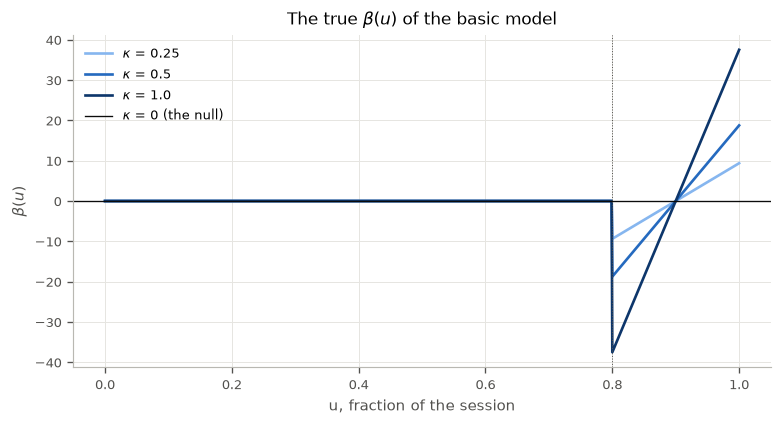

kappa = 1: beta runs from -37.5 at u = 0.8 to +37.5 at u = 1
grid beta vs the line, inside the window: largest relative gap 3.73%


In [12]:
u = np.linspace(0, 1, 1001)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for k, col in zip(KAPPAS[1:], style.ordinal(3)):
    beta_u = np.where(u >= start, k * T * 12 * (u - start - w / 2) / w**3, 0.0)
    ax.plot(u, beta_u, color=col, lw=1.6, label=fr"$\kappa$ = {k}")
ax.axhline(0, color=style.INK, lw=0.8, label=r"$\kappa$ = 0 (the null)")
ax.axvline(start, color=style.MUTED, lw=0.6, ls=":")
ax.set_title(r"The true $\beta(u)$ of the basic model")
ax.set_xlabel("u, fraction of the session")
ax.set_ylabel(r"$\beta(u)$")
ax.legend(loc="upper left")
style.save_figure(fig, "window_jump_beta")
plt.show()

# The grid version that the simulator integrates against, compared with the line above.
beta_grid = wd.window_beta(s, start, kappa=1.0, T=T)
line = T * 12 * (s - start - w / 2) / w**3
inner = on & (s < 1) & (np.abs(line) > 1)        # inside the window, away from its zero
print(f"kappa = 1: beta runs from {line[on][0]:+.1f} at u = 0.8 to {line[on][-1]:+.1f} at u = 1")
print(f"grid beta vs the line, inside the window: largest relative gap "
      f"{np.abs(beta_grid[inner] / line[inner] - 1).max():.2%}")

$\beta(u)$ is zero until 0.8, so nothing before the window matters. Inside the window it is a
straight line through zero at the window's midpoint, 0.9. That is what a slope is: the late
points of the window count positively and the early ones negatively, so a curve that ends
higher than it entered the window has a positive slope. The jump from 0 to $-37.5\kappa$ at
$u = 0.8$ is a genuine discontinuity, which makes this a hard target for a fit built from
smooth functions.

$\beta$ weights the curve's *levels*. The parabola $g$ of 2.2 weights its *returns*. They are
the same functional written two ways.

The simulator integrates against the grid version of $\beta$, which is within 3.7% of this line
inside the window: a regression on 79 points is not quite the continuous one.

## 6. The variance switch

The original proposal also set the night's variance from the window, as its realised variance.
`vol="realised"` does that. Under a GBM it barely matters: the volatility is constant, so the
window's realised variance is the true one plus sampling noise, $(100\sigma)^2\chi^2_{77}/77$.
The cell compares the two at $\kappa = 0.5$, with the same draws.

In [13]:
fixed = sims[0.5]
real = wd.window_jump_sessions(**gbm, start=start, kappa=0.5, vol="realised",
                               rng=np.random.default_rng(0))
ratio = np.sqrt(real["rv"]) / (100 * sigma)
print(f"window realised vol / true vol: from {ratio.min():.3f} to {ratio.max():.3f}, "
      f"sd {ratio.std(ddof=1):.3f}")
print(f"the jumps, fixed vs realised: largest difference {np.abs(real['J'] - fixed['J']).max():.3f}%, "
      f"correlation {np.corrcoef(real['J'], fixed['J'])[0, 1]:.4f}")
print(f"sd(J): fixed {fixed['J'].std(ddof=1):.4f}, realised {real['J'].std(ddof=1):.4f}")

window realised vol / true vol: from 0.786 to 1.207, sd 0.085
the jumps, fixed vs realised: largest difference 0.131%, correlation 0.9980
sd(J): fixed 0.6532, realised 0.6576


The realised volatility stays within about 20% of the truth (standard deviation 0.085,
against the theoretical $1/\sqrt{2 \times 77} = 0.081$). The jumps change by at most 0.13% and
are 0.998 correlated with the fixed-variance ones. The switch also makes the noise
heteroskedastic, which the basic model does not allow, so it stays off by default. A variance
channel that carries real information needs a session volatility that itself varies from day
to day. That is a separate extension of the DGP.

## 7. What this sets up

These data are the basic model with a known answer:

- $\hat d_{t-1}$ is an exactly observed statistic of yesterday's curve. It is exactly
  $N\big(d_\mu,\ \sigma_\varepsilon^2\sum_k g_k^2\Delta s_k\big)$ and i.i.d. over days, and
  almost all of it is the window's realised trend, not the drift;
- the jump responds to it through $\beta(u)$, which is zero before 0.8 and a line after it;
- a dial $\kappa$ runs from the null ($\kappa = 0$) to a jump mostly predictable from the
  session before ($\kappa = 1$, $R^2 = 0.60$).

Next:

1. fit $\beta(u)$ by principal-component regression on yesterday's curve (`jump.jump_eq.fit_mle`)
   and compare it with the line of section 5;
2. test $\beta = 0$ with the exact F test, and measure its power across $\kappa$ and the number
   of days;
3. compare its out-of-sample forecasts with the null's expanding-mean benchmark.